<a href="https://colab.research.google.com/github/Eton-np/DataMining/blob/main/%E0%B9%81%E0%B8%9A%E0%B8%9A%E0%B8%9D%E0%B8%B6%E0%B8%81%E0%B8%AB%E0%B8%B1%E0%B8%94_IQR_Anomaly_Detection_6704800029.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [37]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [51]:
water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2
q1,q3 = np.percentile(water,[25,75])
# q3 = np.percentile(water,75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

mask=(water<low)|(water>high)
print("Q1: ",q1)
print(f"Q3: {q3} IQR: {iqr} Lower: {low} High: {high}")
print(water[mask])


Q1:  175.5
Q3: 185.5 IQR: 10.0 Lower: 160.5 High: 200.5
[420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [52]:
def iqr_outliers(x, k=1.5):
    x = np.array(x,float)
    q1,q3 = np.percentile(x,[25, 75])
    iqr = q3 - q1
    low = q1 - k * iqr
    high = q3 + k * iqr
    mask = (x < low) | (x > high)
    return mask, low, high
    pass

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน

# TODO 2.2
for k in [1.5,3]:
  mask,low,high = iqr_outliers(sales,k)
  print(f"k = {k} mask = {mask.all()} low = {low} high = {high}")

# TODO 2.3 assert
assert iqr_outliers([10,11,12,13,14,15,16,17,18,19,100])[0].tolist() == [False]*10+[True]
assert not iqr_outliers([10,11,12,13,14,15,16,17,18,19])[0].any()
print('ผ่านทุก assert')

k = 1.5 mask = False low = 38.375 high = 67.375
k = 3 mask = False low = 27.5 high = 78.25
ผ่านทุก assert


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

/tmp/ipykernel_874/975452084.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


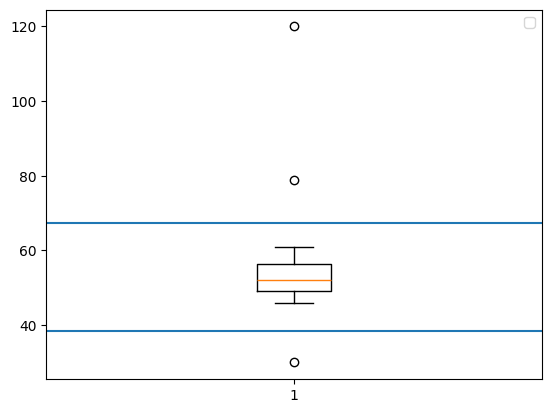

Lower Fence: 38.375
Upper Fence: 67.375
Lower Whisker: 46.0
Upper Whisker: 61.0
IQR Outliers: [120.  79.  30.]
Boxplot Fliers: [ 30. 120.  79.]


In [53]:
# TODO ข้อ 3
mask,lower,upper = iqr_outliers(sales, k=1.5)

boxplot = plt.boxplot(sales, whis=1.5)

plt.axhline(lower)
plt.axhline(upper)

plt.legend()
plt.show()

lower_whisker = boxplot['whiskers'][0].get_ydata()[1]
upper_whisker = boxplot['whiskers'][1].get_ydata()[1]

fliers = boxplot['fliers'][0].get_ydata()

print("Lower Fence:", lower)
print("Upper Fence:", upper)

print("Lower Whisker:", lower_whisker)
print("Upper Whisker:", upper_whisker)

print("IQR Outliers:", sales[mask])
print("Boxplot Fliers:", fliers)

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [56]:
wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# TODO 4.1
mask, lower, upper = iqr_outliers(wage['wage_k'])

print("Lower:", lower)
print("Upper:", upper)
print("Outliers:", wage[mask])
print("จำนวน Outliers:", mask.sum())


# TODO 4.2–4.3
wage['Q1'] = wage.groupby('occupation')['wage_k'].transform('quantile', 0.25)
wage['Q3'] = wage.groupby('occupation')['wage_k'].transform('quantile', 0.75)


wage['IQR'] = wage['Q3'] - wage['Q1']


wage['Lower'] = wage['Q1'] - 1.5 * wage['IQR']
wage['Upper'] = wage['Q3'] + 1.5 * wage['IQR']


wage['Outlier'] = ((wage['wage_k'] < wage['Lower']) |(wage['wage_k'] > wage['Upper']))

print(wage[wage['Outlier']])

Lower: -56.0
Upper: 130.0
Outliers: Empty DataFrame
Columns: [occupation, wage_k]
Index: []
จำนวน Outliers: 0
   occupation  wage_k     Q1     Q3   IQR   Lower   Upper  Outlier
7     cleaner      35  12.00  14.25  2.25   8.625  17.625     True
15      clerk       9  18.75  21.25  2.50  15.000  25.000     True
